In [7]:
import os
print(os.path.exists(r"C:\gym data\gym_churn_us.csv"))
print(os.listdir(r"C:\gym data"))

True
['gym_churn_us.csv']


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv(r"C:\gym data\gym_churn_us.csv")

print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Churn rate (%):", round(df["Churn"].mean() * 100, 2))
df.head()

Shape: (4000, 14)
Missing values: 0
Duplicates: 0
Churn rate (%): 26.52


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0


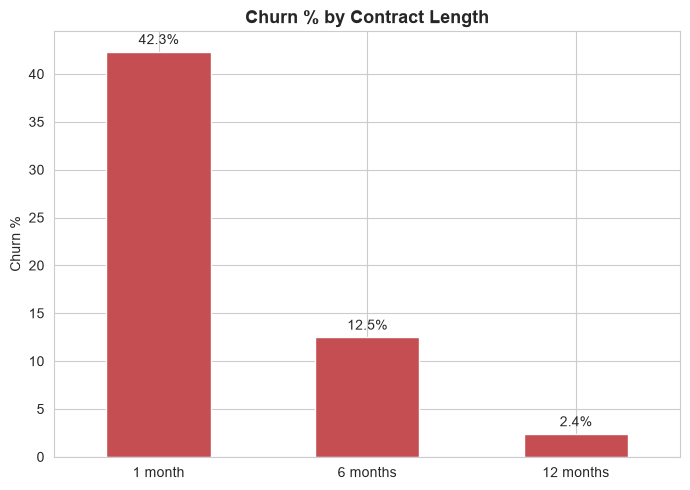

In [2]:
# Helper we'll reuse for the next charts
def churn_bar(col, title, filename, labels=None):
    t = df.groupby(col)["Churn"].mean().mul(100)
    if labels:
        t.index = [labels.get(i, i) for i in t.index]
    ax = t.plot(kind="bar", color="#C44E52", figsize=(7, 5))
    plt.title(title, fontsize=13, weight="bold")
    plt.ylabel("Churn %")
    plt.xlabel("")
    plt.xticks(rotation=0)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%",
                    (p.get_x() + p.get_width() / 2, p.get_height() + 0.8),
                    ha="center")
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

churn_bar("Contract_period",
          "Churn % by Contract Length",
          "01_churn_by_contract.png",
          labels={1: "1 month", 6: "6 months", 12: "12 months"})

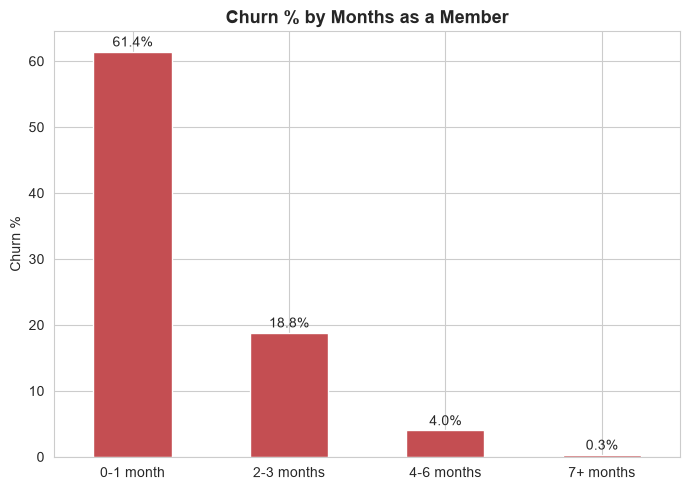

In [3]:
df["tenure_bucket"] = pd.cut(
    df["Lifetime"],
    bins=[-1, 1, 3, 6, 100],
    labels=["0-1 month", "2-3 months", "4-6 months", "7+ months"]
)

churn_bar("tenure_bucket",
          "Churn % by Months as a Member",
          "02_churn_by_tenure.png")

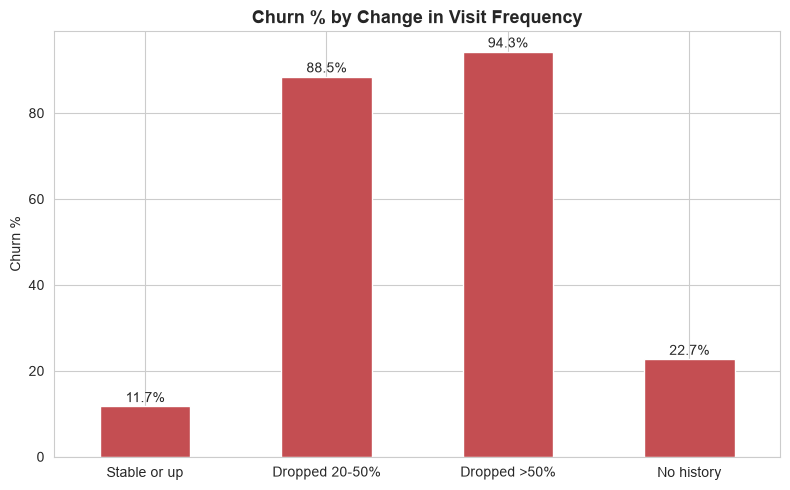

In [4]:
def trend(row):
    if row["Avg_class_frequency_total"] == 0:
        return "No history"
    r = row["Avg_class_frequency_current_month"] / row["Avg_class_frequency_total"]
    if r < 0.5:
        return "Dropped >50%"
    elif r < 0.8:
        return "Dropped 20-50%"
    return "Stable or up"

df["attendance_trend"] = df.apply(trend, axis=1)

order = ["Stable or up", "Dropped 20-50%", "Dropped >50%", "No history"]
t = df.groupby("attendance_trend")["Churn"].mean().mul(100).reindex(order)

ax = t.plot(kind="bar", color="#C44E52", figsize=(8, 5))
plt.title("Churn % by Change in Visit Frequency", fontsize=13, weight="bold")
plt.ylabel("Churn %")
plt.xlabel("")
plt.xticks(rotation=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%",
                (p.get_x() + p.get_width() / 2, p.get_height() + 1),
                ha="center")
plt.tight_layout()
plt.savefig("03_churn_by_attendance.png", dpi=150)
plt.show()

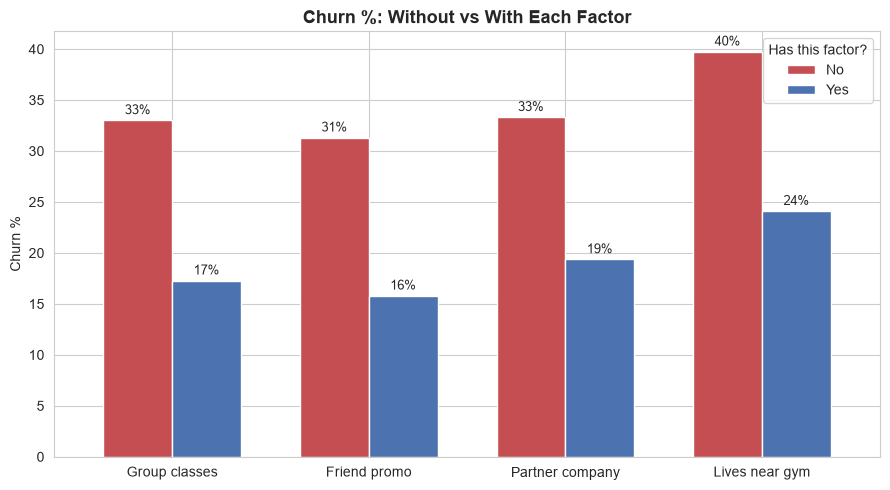

In [5]:
factors = {
    "Group classes": "Group_visits",
    "Friend promo": "Promo_friends",
    "Partner company": "Partner",
    "Lives near gym": "Near_Location",
}

rows = []
for name, col in factors.items():
    rates = df.groupby(col)["Churn"].mean().mul(100)
    rows.append({"Factor": name, "No": rates[0], "Yes": rates[1]})
res = pd.DataFrame(rows).set_index("Factor")

ax = res.plot(kind="bar", color=["#C44E52", "#4C72B0"], figsize=(9, 5), width=0.7)
plt.title("Churn %: Without vs With Each Factor", fontsize=13, weight="bold")
plt.ylabel("Churn %")
plt.xlabel("")
plt.xticks(rotation=0)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.0f}%",
                (p.get_x() + p.get_width() / 2, p.get_height() + 0.6),
                ha="center", fontsize=9)
plt.legend(title="Has this factor?")
plt.tight_layout()
plt.savefig("04_retention_factors.png", dpi=150)
plt.show()

In [6]:
out = df.copy()

# Readable labels
out["Churn_Status"] = out["Churn"].map({0: "Stayed", 1: "Left"})
out["Contract"] = out["Contract_period"].map({1: "1 month", 6: "6 months", 12: "12 months"})
out["Group_Classes"] = out["Group_visits"].map({0: "No", 1: "Yes"})
out["Friend_Promo"] = out["Promo_friends"].map({0: "No", 1: "Yes"})
out["Partner_Company"] = out["Partner"].map({0: "No", 1: "Yes"})
out["Near_Gym"] = out["Near_Location"].map({0: "No", 1: "Yes"})

# Visit ratio and at-risk flag (still a member, visits dropped by half or more)
out["visit_ratio"] = np.where(
    out["Avg_class_frequency_total"] > 0,
    out["Avg_class_frequency_current_month"] / out["Avg_class_frequency_total"],
    np.nan
)
out["At_Risk"] = np.where(
    (out["Churn"] == 0) & (out["visit_ratio"] < 0.5), "At risk", "Not flagged"
)

out["tenure_bucket"] = out["tenure_bucket"].astype(str)

out.to_csv("gym_churn_for_powerbi.csv", index=False)
print("Saved:", out.shape)
print(out["At_Risk"].value_counts())

Saved: (4000, 24)
At_Risk
Not flagged    3979
At risk          21
Name: count, dtype: int64
